# Day 2 — Customer and Restaurant Segmentation

## Objective
Use unsupervised learning to identify useful customer and restaurant groups from the synthetic Uber Eats datasets.

**Workflow:** feature engineering → missing-value treatment → standardization → K-Means → PCA visualization → DBSCAN diagnostics → business interpretation.

## 1. Load libraries and datasets

We load the source tables and create output folders. IDs are used to connect tables, but they will not be used as model features.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Locate the project root whether the notebook is opened from the root or notebooks/.
possible_roots = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
PROJECT_ROOT = next(
    (path.resolve() for path in possible_roots if (path / "data" / "raw").exists()),
    Path.cwd().resolve()
)

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

customers = pd.read_csv(RAW_DIR / "customers.csv")
restaurants = pd.read_csv(RAW_DIR / "restaurants.csv")
orders = pd.read_csv(
    RAW_DIR / "orders.csv",
    parse_dates=["order_timestamp"]
)
deliveries = pd.read_csv(RAW_DIR / "deliveries.csv")
reviews = pd.read_csv(RAW_DIR / "reviews.csv")

print(f"Project root: {PROJECT_ROOT}")
print(f"Customers: {customers.shape}")
print(f"Restaurants: {restaurants.shape}")
print(f"Orders: {orders.shape}")
print(f"Deliveries: {deliveries.shape}")
print(f"Reviews: {reviews.shape}")

Project root: /home/nineleaps-admin/uber-eats-intelligence
Customers: (2000, 6)
Restaurants: (100, 6)
Orders: (10000, 8)
Deliveries: (8808, 10)
Reviews: (5968, 8)


## 2. Customer feature engineering

We use completed orders to measure purchasing behavior. Ordering frequency is defined as completed orders per active calendar month. Average ratings are calculated only for customers who submitted reviews.

In [2]:
# Keep completed orders for purchasing measures.
completed_orders = orders.loc[
    orders["order_status"].eq("Completed")
].copy()

# Create a month field to calculate each customer's active months.
completed_orders["order_month"] = (
    completed_orders["order_timestamp"].dt.to_period("M")
)

# Aggregate order behavior for each customer.
customer_order_features = (
    completed_orders.groupby("customer_id")
    .agg(
        total_orders=("order_id", "count"),
        average_order_value=("order_amount", "mean"),
        total_spending=("order_amount", "sum"),
        weekend_orders=(
            "order_timestamp",
            lambda dates: int((dates.dt.day_of_week >= 5).sum())
        ),
        late_night_orders=(
            "order_timestamp",
            lambda dates: int(
                ((dates.dt.hour >= 22) | (dates.dt.hour < 5)).sum()
            )
        )
    )
    .reset_index()
)

# Count the number of calendar months in which each customer ordered.
active_months = (
    completed_orders.groupby("customer_id")["order_month"]
    .nunique()
    .rename("active_months")
    .reset_index()
)

customer_order_features = customer_order_features.merge(
    active_months,
    on="customer_id",
    how="left"
)

customer_order_features["ordering_frequency"] = (
    customer_order_features["total_orders"]
    / customer_order_features["active_months"].clip(lower=1)
)

customer_order_features = customer_order_features.drop(
    columns=["active_months"]
)

# Calculate ratings only from reviews that actually exist.
customer_ratings = (
    reviews.groupby("customer_id")["rating"]
    .mean()
    .rename("average_rating_given")
    .reset_index()
)

# Keep every customer, including customers with no completed orders.
customer_features = (
    customers[["customer_id"]]
    .merge(customer_order_features, on="customer_id", how="left")
    .merge(customer_ratings, on="customer_id", how="left")
)

# No-order customers have zero purchasing activity.
purchase_columns = [
    "total_orders",
    "average_order_value",
    "total_spending",
    "weekend_orders",
    "late_night_orders",
    "ordering_frequency"
]
customer_features[purchase_columns] = (
    customer_features[purchase_columns].fillna(0)
)

display(customer_features.head())
print("Customer feature table shape:", customer_features.shape)

,customer_id,total_orders,average_order_value,total_spending,weekend_orders,late_night_orders,ordering_frequency,average_rating_given
0,1,6.0,588.305000,3529.83,3.0,0.0,1.000000,3.80
1,2,4.0,579.452500,2317.81,1.0,2.0,1.000000,3.50
2,3,4.0,568.025000,2272.10,0.0,2.0,1.333333,4.50
3,4,4.0,631.935000,2527.74,1.0,1.0,1.000000,2.75
4,5,7.0,515.434286,3608.04,2.0,4.0,1.166667,4.00


Customer feature table shape: (2000, 8)


**Observation:** Review the feature table and confirm that customers without completed orders have zero purchasing measures. A missing average rating means the customer has not submitted a review; it is not the same as a zero rating.

**Next:** Build comparable restaurant-level operational and revenue features.

## 3. Restaurant feature engineering

Revenue and completed-order counts use completed orders only. Cancellation rate uses all orders placed at each restaurant. Preparation and delivery averages use available delivery records.

In [3]:
# Count all orders and cancellations for each restaurant.
all_order_summary = (
    orders.groupby("restaurant_id")
    .agg(
        all_orders=("order_id", "count"),
        cancelled_orders=(
            "order_status",
            lambda status: int(status.eq("Cancelled").sum())
        )
    )
    .reset_index()
)

# Calculate revenue and completed-order counts.
completed_order_summary = (
    completed_orders.groupby("restaurant_id")
    .agg(
        total_orders=("order_id", "count"),
        revenue=("order_amount", "sum")
    )
    .reset_index()
)

# Attach restaurant IDs to delivery records to calculate operational measures.
delivery_with_restaurants = deliveries.merge(
    orders[["order_id", "restaurant_id"]],
    on="order_id",
    how="left"
)

delivery_summary = (
    delivery_with_restaurants.groupby("restaurant_id")
    .agg(
        average_preparation_time=("preparation_time_minutes", "mean"),
        average_delivery_time=("delivery_time_minutes", "mean")
    )
    .reset_index()
)

restaurant_rating_summary = (
    reviews.groupby("restaurant_id")["rating"]
    .mean()
    .rename("average_rating")
    .reset_index()
)

# Start with all restaurants so those without orders are retained.
restaurant_features = (
    restaurants[["restaurant_id"]]
    .merge(completed_order_summary, on="restaurant_id", how="left")
    .merge(all_order_summary, on="restaurant_id", how="left")
    .merge(delivery_summary, on="restaurant_id", how="left")
    .merge(restaurant_rating_summary, on="restaurant_id", how="left")
)

# Missing order counts and revenue mean no recorded completed orders.
count_columns = [
    "total_orders", "revenue", "all_orders", "cancelled_orders"
]
restaurant_features[count_columns] = (
    restaurant_features[count_columns].fillna(0)
)

restaurant_features["cancellation_rate"] = np.where(
    restaurant_features["all_orders"] > 0,
    restaurant_features["cancelled_orders"] / restaurant_features["all_orders"],
    0
)

restaurant_features = restaurant_features.drop(
    columns=["all_orders", "cancelled_orders"]
)

display(restaurant_features.head())
print("Restaurant feature table shape:", restaurant_features.shape)

,restaurant_id,total_orders,revenue,average_preparation_time,average_delivery_time,average_rating,cancellation_rate
0,1,98,58977.27,26.561290,38.012903,3.724638,0.066667
1,2,84,50382.78,25.590123,38.328395,3.400000,0.096774
2,3,96,58984.04,25.054737,38.720000,3.722222,0.119266
3,4,98,66611.85,26.644211,43.795789,3.421875,0.084112
4,5,102,65323.36,25.946000,37.114000,3.938462,0.097345


Restaurant feature table shape: (100, 7)


## 4. Prepare and standardize model features

Features use different units: spending is measured in currency, counts are numbers of orders, and ratings use a 1–5 scale. `StandardScaler` puts numerical features on a comparable scale before distance-based clustering.

We exclude customer and restaurant IDs because identifiers do not describe behavior.

In [4]:
customer_feature_columns = [
    "total_orders",
    "average_order_value",
    "total_spending",
    "ordering_frequency",
    "average_rating_given",
    "weekend_orders",
    "late_night_orders"
]

restaurant_feature_columns = [
    "total_orders",
    "revenue",
    "average_rating",
    "average_preparation_time",
    "cancellation_rate",
    "average_delivery_time"
]

def scale_model_features(dataframe, feature_columns):
    """Impute missing numeric values with column medians, then standardize."""
    model_data = dataframe[feature_columns].copy()
    model_data = model_data.replace([np.inf, -np.inf], np.nan)
    model_data = model_data.fillna(model_data.median())

    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(model_data)

    return model_data, scaled_data, scaler

customer_model_data, customer_scaled, customer_scaler = scale_model_features(
    customer_features, customer_feature_columns
)
restaurant_model_data, restaurant_scaled, restaurant_scaler = scale_model_features(
    restaurant_features, restaurant_feature_columns
)

print("Customer model matrix:", customer_scaled.shape)
print("Restaurant model matrix:", restaurant_scaled.shape)

Customer model matrix: (2000, 7)
Restaurant model matrix: (100, 6)


## 5. K-Means: compare candidate cluster counts

The elbow method shows how within-cluster variation changes as the number of clusters increases. Silhouette score gives another measure of how well-separated the clusters are. We review both metrics before interpreting the groups.

Customer K-Means evaluation


,k,inertia,silhouette_score
0,2,10277.408,0.237
1,3,9146.057,0.159
2,4,8302.810,0.157
3,5,7637.848,0.155
4,6,7056.569,0.164


Restaurant K-Means evaluation


,k,inertia,silhouette_score
0,2,438.774,0.235
1,3,376.681,0.224
2,4,338.361,0.171
3,5,304.344,0.175
4,6,278.998,0.176


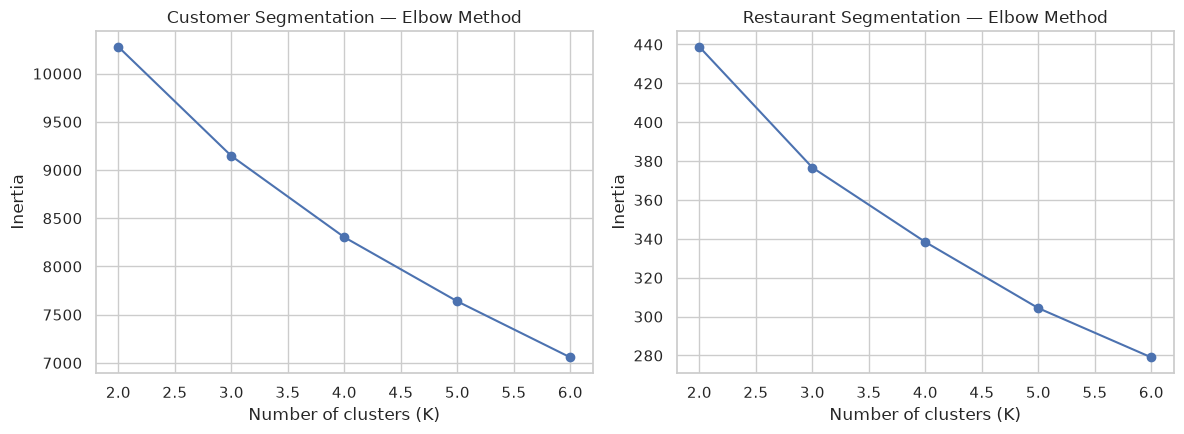

In [5]:
def evaluate_kmeans_candidates(scaled_data, maximum_k=6):
    """Return inertia and silhouette score for a small range of K values."""
    results = []
    upper_k = min(maximum_k, len(scaled_data) - 1)

    for k in range(2, upper_k + 1):
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )
        labels = model.fit_predict(scaled_data)

        results.append({
            "k": k,
            "inertia": model.inertia_,
            "silhouette_score": silhouette_score(scaled_data, labels)
        })

    return pd.DataFrame(results)

customer_k_results = evaluate_kmeans_candidates(customer_scaled)
restaurant_k_results = evaluate_kmeans_candidates(restaurant_scaled)

print("Customer K-Means evaluation")
display(customer_k_results.round(3))

print("Restaurant K-Means evaluation")
display(restaurant_k_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(
    customer_k_results["k"],
    customer_k_results["inertia"],
    marker="o"
)
axes[0].set_title("Customer Segmentation — Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    restaurant_k_results["k"],
    restaurant_k_results["inertia"],
    marker="o"
)
axes[1].set_title("Restaurant Segmentation — Elbow Method")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Inertia")

plt.tight_layout()
plt.show()

## 6. Fit K-Means and interpret cluster profiles

We use silhouette scores to help shortlist a candidate K, then inspect the original-scale cluster profiles. Cluster numbers are arbitrary labels; the profile averages help explain what each group represents.

In [6]:
# Select a candidate K with the best silhouette score in the tested range.
customer_k = int(
    customer_k_results.loc[
        customer_k_results["silhouette_score"].idxmax(), "k"
    ]
)
restaurant_k = int(
    restaurant_k_results.loc[
        restaurant_k_results["silhouette_score"].idxmax(), "k"
    ]
)

customer_kmeans = KMeans(
    n_clusters=customer_k,
    random_state=42,
    n_init=10
)
restaurant_kmeans = KMeans(
    n_clusters=restaurant_k,
    random_state=42,
    n_init=10
)

customer_features["kmeans_cluster"] = customer_kmeans.fit_predict(customer_scaled)
restaurant_features["kmeans_cluster"] = restaurant_kmeans.fit_predict(restaurant_scaled)

customer_silhouette = silhouette_score(
    customer_scaled, customer_features["kmeans_cluster"]
)
restaurant_silhouette = silhouette_score(
    restaurant_scaled, restaurant_features["kmeans_cluster"]
)

print(
    f"Customer segmentation: K={customer_k}, "
    f"silhouette={customer_silhouette:.3f}"
)
customer_cluster_profile = (
    customer_features.groupby("kmeans_cluster")[customer_feature_columns]
    .mean()
    .round(2)
)
display(customer_cluster_profile)

print(
    f"Restaurant segmentation: K={restaurant_k}, "
    f"silhouette={restaurant_silhouette:.3f}"
)
restaurant_cluster_profile = (
    restaurant_features.groupby("kmeans_cluster")[restaurant_feature_columns]
    .mean()
    .round(2)
)
display(restaurant_cluster_profile)

Customer segmentation: K=2, silhouette=0.237


,total_orders,average_order_value,total_spending,ordering_frequency,average_rating_given,weekend_orders,late_night_orders
kmeans_cluster,,,,,,,
0,3.16,610.92,1948.80,1.09,3.79,0.76,0.75
1,6.36,666.59,4200.29,1.31,3.72,2.00,2.04


Restaurant segmentation: K=2, silhouette=0.235


,total_orders,revenue,average_rating,average_preparation_time,cancellation_rate,average_delivery_time
kmeans_cluster,,,,,,
0,84.10,52998.67,3.67,25.87,0.11,39.22
1,96.96,63398.02,3.82,26.16,0.08,38.94


**Observation:** Use the profile tables to describe the groups based on their actual average spending, order frequency, ratings, and operational measures. Do not assume that a higher cluster number means better performance.

**Next:** Use PCA to create a two-dimensional visual overview of the K-Means groups.

## 7. Visualize clusters using PCA

PCA reduces the scaled feature matrix to two dimensions for plotting. This helps us view the groups, but the plot alone does not prove that the clusters are meaningful.

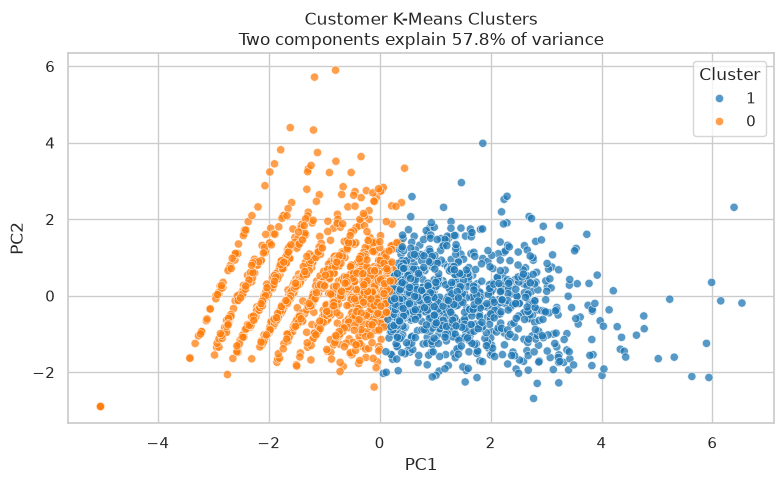

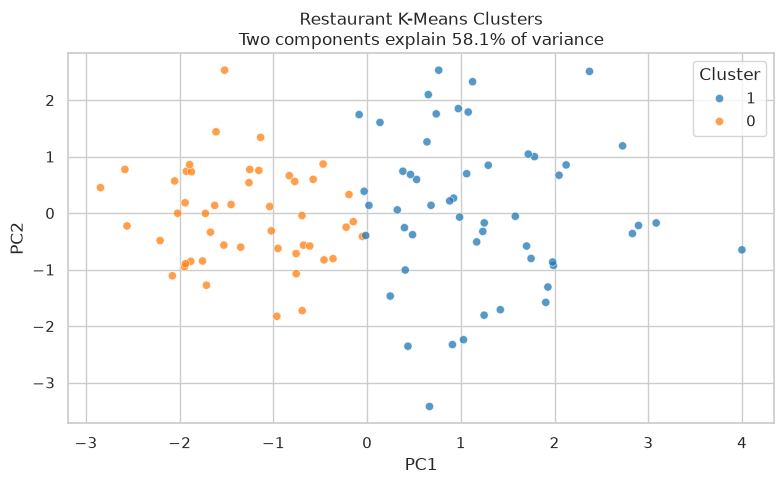

In [7]:
def plot_pca_clusters(scaled_data, cluster_labels, chart_title):
    """Plot clusters after projecting scaled features into two PCA components."""
    pca = PCA(n_components=2, random_state=42)
    points = pca.fit_transform(scaled_data)

    plot_data = pd.DataFrame({
        "PC1": points[:, 0],
        "PC2": points[:, 1],
        "Cluster": pd.Series(cluster_labels).astype(str).to_numpy()
    })

    explained_variance = pca.explained_variance_ratio_.sum()

    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=plot_data,
        x="PC1",
        y="PC2",
        hue="Cluster",
        palette="tab10",
        alpha=0.75,
        s=35
    )
    plt.title(
        f"{chart_title}\nTwo components explain {explained_variance:.1%} of variance"
    )
    plt.tight_layout()
    plt.show()

plot_pca_clusters(
    customer_scaled,
    customer_features["kmeans_cluster"],
    "Customer K-Means Clusters"
)

plot_pca_clusters(
    restaurant_scaled,
    restaurant_features["kmeans_cluster"],
    "Restaurant K-Means Clusters"
)

## 8. DBSCAN: inspect dense groups and noise points

DBSCAN identifies dense groups and marks observations outside those groups as noise (`-1`). Its output depends on `eps` and `min_samples`, so we compare a small range of `eps` values.

A silhouette score is reported only when at least two non-noise clusters exist and the score is mathematically valid.

In [8]:
def evaluate_dbscan(scaled_data, eps_values, min_samples):
    """Summarize DBSCAN cluster counts, noise percentage, and valid silhouette."""
    results = []

    for eps in eps_values:
        labels = DBSCAN(
            eps=eps,
            min_samples=min_samples
        ).fit_predict(scaled_data)

        non_noise_mask = labels != -1
        cluster_ids = set(labels[non_noise_mask])
        noise_count = int((labels == -1).sum())
        silhouette = np.nan

        if len(cluster_ids) >= 2 and non_noise_mask.sum() > len(cluster_ids):
            try:
                silhouette = silhouette_score(
                    scaled_data[non_noise_mask],
                    labels[non_noise_mask]
                )
            except ValueError:
                silhouette = np.nan

        results.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters_excluding_noise": len(cluster_ids),
            "noise_points": noise_count,
            "noise_percent": round(100 * noise_count / len(labels), 2),
            "silhouette_non_noise": silhouette
        })

    return pd.DataFrame(results)

eps_candidates = [0.8, 1.0, 1.2, 1.5, 1.8, 2.0]

customer_dbscan_results = evaluate_dbscan(
    customer_scaled,
    eps_values=eps_candidates,
    min_samples=10
)
restaurant_dbscan_results = evaluate_dbscan(
    restaurant_scaled,
    eps_values=eps_candidates,
    min_samples=5
)

print("Customer DBSCAN diagnostics")
display(customer_dbscan_results.round(3))

print("Restaurant DBSCAN diagnostics")
display(restaurant_dbscan_results.round(3))

Customer DBSCAN diagnostics


,eps,min_samples,clusters_excluding_noise,noise_points,noise_percent,silhouette_non_noise
0,0.8,10,12,1451,72.55,0.155
1,1.0,10,3,704,35.20,0.087
2,1.2,10,2,313,15.65,0.524
3,1.5,10,2,93,4.65,0.501
4,1.8,10,2,26,1.30,0.492
5,2.0,10,2,14,0.70,0.489


Restaurant DBSCAN diagnostics


,eps,min_samples,clusters_excluding_noise,noise_points,noise_percent,silhouette_non_noise
0,0.8,5,0,100,100.0,NaN
1,1.0,5,0,100,100.0,NaN
2,1.2,5,3,80,80.0,0.265
3,1.5,5,1,42,42.0,NaN
4,1.8,5,1,14,14.0,NaN
5,2.0,5,1,5,5.0,NaN


**Observation:** Compare the number of clusters, noise percentage, and valid silhouette together. A high silhouette score alone is not enough: one-cluster results are not a useful multi-cluster segmentation, and excessive noise can leave only a small subset of observations grouped.

If none of the tested configurations produces useful groups, report that limitation instead of forcing a result.

## 9. Save feature tables and review cluster sizes

We save the engineered tables with their K-Means labels so they can be reused in later analysis. The files remain in `data/processed/`.

In [9]:
customer_features.to_csv(
    PROCESSED_DIR / "customer_features.csv",
    index=False
)
restaurant_features.to_csv(
    PROCESSED_DIR / "restaurant_features.csv",
    index=False
)

print(f"Saved customer features to: {PROCESSED_DIR / 'customer_features.csv'}")
print(f"Saved restaurant features to: {PROCESSED_DIR / 'restaurant_features.csv'}")

print("Customer cluster sizes")
display(
    customer_features["kmeans_cluster"]
    .value_counts()
    .sort_index()
    .rename("customer_count")
    .to_frame()
)

print("Restaurant cluster sizes")
display(
    restaurant_features["kmeans_cluster"]
    .value_counts()
    .sort_index()
    .rename("restaurant_count")
    .to_frame()
)

Saved customer features to: /home/nineleaps-admin/uber-eats-intelligence/data/processed/customer_features.csv
Saved restaurant features to: /home/nineleaps-admin/uber-eats-intelligence/data/processed/restaurant_features.csv
Customer cluster sizes


,customer_count
kmeans_cluster,
0,1137
1,863


Restaurant cluster sizes


,restaurant_count
kmeans_cluster,
0,48
1,52
